# RE03-B | Laboratorio 2: exploración, visualización e ingeniería de características

**Curso:** Analítica de Datos – Ingeniería Industrial  
**Profesor autor:** Carlos Alberto Figueroa Martínez  
**Caso:** Industrias Nova S.A.S.  

> **Propósito:** explorar un conjunto de datos industriales integrado, construir visualizaciones que permitan reconocer patrones, detectar anomalías, examinar relaciones entre variables y preparar características con sentido operacional para análisis posteriores.

### Evidencias que debes producir
Al finalizar este notebook debes:
1. **Ejecutar todas las celdas** y verificar que no existan errores.
2. Formular **al menos tres hallazgos sustentados** en tablas o visualizaciones.
3. Construir **dos nuevas variables** con sentido operacional y explicar su utilidad.
4. Registrar qué variables **conservarías o descartarías** y justificar la decisión.
5. Responder las preguntas orientadoras:
   - ¿Qué patrón es relevante para una decisión?
   - ¿Correlación implica causalidad?
   - ¿Qué anomalía requiere investigación del proceso?

**Nota:** este notebook no reemplaza la bitácora del Laboratorio 1. Si trabajas con el archivo RAW suministrado por el profesor, la sección de preparación aplica una estandarización mínima para que la exploración sea reproducible; compárala con las decisiones documentadas en tu bitácora.

## 0. Preparación del entorno

Ejecuta la siguiente celda. El notebook utiliza `pandas`, `numpy`, `matplotlib` y herramientas de `scikit-learn`.

In [1]:
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import IsolationForest, RandomForestRegressor
from sklearn.preprocessing import StandardScaler

pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.grid"] = True

print("Entorno listo.")

Entorno listo.


## 1. Localiza y carga el archivo del Laboratorio 1

El notebook buscará primero una versión depurada creada por el estudiante y, si no existe, utilizará el dataset suministrado por el profesor.

In [2]:
CANDIDATOS = [
    Path("RE02D_-_Dataset_integral_1.xlsx"),   # nombre del archivo recibido
    Path("Lab1_DatosLimpios.xlsx"),
    Path("RE02_Dataset_Industrial.xlsx"),
    Path("RE02B_Dataset_Laboratorio1_Datos_Industriales.xlsx"),
    Path("/mnt/data/RE02_Dataset_Industrial.xlsx"),
    Path("/mnt/data/RE02B_Dataset_Laboratorio1_Datos_Industriales.xlsx"),
]

archivo = next((p for p in CANDIDATOS if p.exists()), None)
if archivo is None:
    raise FileNotFoundError(
        "No se encontró el archivo del Laboratorio 1. Copia el Excel en la misma carpeta del notebook "
        "o actualiza la variable CANDIDATOS."
    )

print("Archivo utilizado:", archivo)

hojas = {
    "ordenes": "Ordenes_Produccion",
    "eventos": "Eventos_Maquina",
    "defectos": "Defectos",
    "inventarios": "Inventarios",
    "entregas": "Entregas",
}

datos = {k: pd.read_excel(archivo, sheet_name=v, header=3) for k, v in hojas.items()}
for nombre, df in datos.items():
    print(f"{nombre:12s} -> {df.shape[0]:3d} filas x {df.shape[1]:2d} columnas")

Archivo utilizado: RE02D_-_Dataset_integral_1.xlsx
ordenes      ->  61 filas x 11 columnas
eventos      -> 151 filas x  8 columnas
defectos     ->  91 filas x  9 columnas
inventarios  -> 101 filas x 10 columnas
entregas     ->  61 filas x 10 columnas


## 2. Preparación mínima y control de estructura

Esta sección **no pretende resolver nuevamente el Laboratorio 1**. Su función es asegurar tipos básicos, retirar duplicados de identificadores y normalizar códigos evidentes para poder construir la tabla analítica.

In [3]:
def normalizar_codigo(serie):
    return (serie.astype("string")
            .str.strip()
            .str.upper()
            .str.replace("-", "", regex=False)
            .str.replace("_", "", regex=False))

ordenes = datos["ordenes"].copy()
eventos = datos["eventos"].copy()
defectos = datos["defectos"].copy()
inventarios = datos["inventarios"].copy()
entregas = datos["entregas"].copy()

# Identificadores y texto
for df, cols in [
    (ordenes, ["orden_id","producto_id","maquina_id","turno","estado"]),
    (eventos, ["evento_id","maquina_id","orden_id","tipo_evento","causa"]),
    (defectos, ["defecto_id","orden_id","producto_id","maquina_id","tipo_defecto","severidad","tipo_inspeccion"]),
    (inventarios, ["registro_inv_id","bodega","producto_id","unidad"]),
    (entregas, ["entrega_id","orden_id","cliente_id","producto_id","ciudad","estado_entrega"]),
]:
    for c in cols:
        if c in df.columns:
            df[c] = df[c].astype("string").str.strip()

for df, cols in [
    (ordenes,["producto_id","maquina_id"]),
    (eventos,["maquina_id"]),
    (defectos,["producto_id","maquina_id"]),
    (inventarios,["producto_id"]),
    (entregas,["producto_id"]),
]:
    for c in cols:
        df[c] = normalizar_codigo(df[c])

# Fechas
for df, cols in [
    (ordenes,["inicio_plan","fin_plan","inicio_real","fin_real"]),
    (eventos,["inicio_evento","fin_evento"]),
    (defectos,["fecha_hora"]),
    (inventarios,["fecha"]),
    (entregas,["fecha_prometida","fecha_real"]),
]:
    for c in cols:
        df[c] = pd.to_datetime(df[c], errors="coerce")

# Numéricos
for df, cols in [
    (ordenes,["cantidad_plan","cantidad_buena"]),
    (eventos,["duracion_reportada_min"]),
    (defectos,["cantidad_defectos"]),
    (inventarios,["inventario_inicial","entradas","salidas","inventario_final_reportado","punto_reorden"]),
    (entregas,["unidades_entregadas","dias_retraso_reportado"]),
]:
    for c in cols:
        df[c] = pd.to_numeric(df[c], errors="coerce")

# Identificadores únicos: conservamos la primera ocurrencia para el análisis exploratorio.
ordenes = ordenes.drop_duplicates("orden_id", keep="first")
eventos = eventos.drop_duplicates("evento_id", keep="first")
defectos = defectos.drop_duplicates("defecto_id", keep="first")
inventarios = inventarios.drop_duplicates("registro_inv_id", keep="first")
entregas = entregas.drop_duplicates("entrega_id", keep="first")

print("Preparación mínima finalizada.")

Preparación mínima finalizada.


In [4]:
# 2.1 Correcciones adicionales evidentes (detectadas en el perfil y en las tablas RAW)
# Solo se corrige lo que tiene evidencia directa en el propio dataset; lo demás se deja y se documenta.
n_turno = (~ordenes["turno"].isin(["A","B","C"])).sum()
n_estado = (ordenes["estado"] != ordenes["estado"].str.capitalize()).sum()
ordenes["turno"] = ordenes["turno"].str.extract(r"([ABC])\s*$")[0]            # 'Turno A' -> 'A'
ordenes["estado"] = ordenes["estado"].str.capitalize()                         # 'cerrada' -> 'Cerrada'

maq_invalida = ~ordenes["maquina_id"].str.fullmatch(r"M0[1-6]").fillna(False)  # M99 no existe en Maestros (M01-M06)
ordenes.loc[maq_invalida, "maquina_id"] = pd.NA

plan_invalido = ordenes["cantidad_plan"] <= 0                                  # cantidad_plan debe ser > 0
ordenes.loc[plan_invalido, "cantidad_plan"] = np.nan

fecha_inconsistente = ordenes["inicio_plan"] > ordenes["fin_plan"]             # inicio posterior al fin planificado
ordenes.loc[fecha_inconsistente, "inicio_plan"] = pd.NaT

print(f"turno normalizado: {n_turno} | estado normalizado: {n_estado} | maquina inválida -> vacío: {int(maq_invalida.sum())} | "
      f"cantidad_plan<=0 -> vacío: {int(plan_invalido.sum())} | inicio_plan inconsistente -> vacío: {int(fecha_inconsistente.sum())}")
print("Turnos:", ordenes["turno"].value_counts().to_dict())
print("Máquinas:", ordenes["maquina_id"].value_counts(dropna=False).to_dict())

turno normalizado: 1 | estado normalizado: 1 | maquina inválida -> vacío: 1 | cantidad_plan<=0 -> vacío: 1 | inicio_plan inconsistente -> vacío: 1
Turnos: {'A': 29, 'C': 16, 'B': 15}
Máquinas: {'M01': 12, 'M06': 12, 'M05': 10, 'M02': 9, 'M03': 8, 'M04': 8, <NA>: 1}


## 3. Perfil exploratorio inicial

Antes de visualizar, revisa el tamaño, los faltantes y la variabilidad. Un patrón útil depende de la calidad y del contexto de la variable.

In [5]:
def perfil(df, nombre):
    return pd.DataFrame({
        "tabla": nombre,
        "variable": df.columns,
        "tipo": [str(df[c].dtype) for c in df.columns],
        "faltantes": [df[c].isna().sum() for c in df.columns],
        "faltantes_pct": [100*df[c].isna().mean() for c in df.columns],
        "unicos": [df[c].nunique(dropna=True) for c in df.columns],
    })

perfil_general = pd.concat([
    perfil(ordenes,"Ordenes"), perfil(eventos,"Eventos"), perfil(defectos,"Defectos"),
    perfil(inventarios,"Inventarios"), perfil(entregas,"Entregas")
], ignore_index=True)

perfil_general.sort_values(["faltantes_pct","tabla"], ascending=[False,True]).head(20)

,tabla,variable,tipo,faltantes,faltantes_pct,unicos
43,Entregas,fecha_real,datetime64[us],1,1.67,30
2,Ordenes,maquina_id,string,1,1.67,6
3,Ordenes,inicio_plan,datetime64[us],1,1.67,50
7,Ordenes,cantidad_plan,float64,1,1.67,8
8,Ordenes,cantidad_buena,float64,1,1.67,42
26,Defectos,severidad,string,1,1.11,3
35,Inventarios,inventario_final_reportado,float64,1,1.00,86
17,Eventos,causa,string,1,0.67,7
19,Defectos,defecto_id,string,0,0.00,90
20,Defectos,orden_id,string,0,0.00,45


### 3.1 Pregunta de lectura

Identifica una variable con faltantes o baja variabilidad y explica por qué podría limitar un análisis posterior.

**Respuesta 3.1 – Variables con faltantes o baja variabilidad**
- **`Entregas.fecha_real`** (1 faltante, 1.7%) corresponde a `ENT0006` (orden `OP0006`, máquina M01). Con esa fecha vacía, `dias_retraso_calculado` queda sin valor justo en una orden que el propio sistema reporta con **7 días de retraso** (el máximo), de modo que el análisis de retrasos **subestima** el problema de M01. Se dejó vacía en vez de imputarla.
- **`cantidad_buena`** (1 faltante, `OP0014`) impide calcular cumplimiento y ciclo de esa orden.
- **Baja variabilidad:** `estado` es constante una vez normalizado (60 de 60 "Cerrada") y `Entregas.estado_entrega` es casi constante ("Entregada"); no sirven para explicar nada. Además, `minutos_parada` es 0 en más de la mitad de las órdenes, lo que obliga a usar medianas y métodos robustos.
- **Faltantes "escondidos":** hay valores presentes pero inválidos (`cantidad_plan = 0`, máquina `M99`, turno `Turno A`, `inicio_plan` posterior a `fin_plan`); la sección 2.1 los corrige o los deja vacíos de forma explícita.


In [6]:
ordenes.describe(include="all", datetime_is_numeric=True).T if "datetime_is_numeric" in pd.DataFrame.describe.__code__.co_varnames else ordenes.describe(include="all").T

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
orden_id,60,60,OP0001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
producto_id,60,8,P005,12,NaN,NaN,NaN,NaN,NaN,NaN,NaN
maquina_id,59,6,M01,12,NaN,NaN,NaN,NaN,NaN,NaN,NaN
inicio_plan,59,NaN,NaN,NaN,2026-08-26 17:18:18.305084,2026-08-03 23:00:00,2026-08-14 23:00:00,2026-08-28 15:00:00,2026-09-06 15:00:00,2026-09-17 15:00:00,NaN
fin_plan,60,NaN,NaN,NaN,2026-08-27 02:13:08.571033,2026-08-04 12:08:34.285000,2026-08-15 12:34:17.142250,2026-08-28 20:42:51.428000,2026-09-07 02:08:34.285250,2026-09-18 01:17:08.571000,NaN
inicio_real,60,NaN,NaN,NaN,2026-08-26 16:22:00,2026-08-03 23:00:00,2026-08-15 05:00:00,2026-08-28 08:00:00,2026-09-06 15:00:00,2026-09-17 17:00:00,NaN
fin_real,60,NaN,NaN,NaN,2026-08-27 05:56:08.571033,2026-08-04 13:08:34.285000,2026-08-15 20:34:17.142250,2026-08-28 23:42:51.428000,2026-09-07 02:08:34.285250,2026-09-18 05:17:08.571000,NaN
cantidad_plan,59.00,NaN,NaN,NaN,150.00,80.00,100.00,150.00,180.00,300.00,58.96
cantidad_buena,59.00,NaN,NaN,NaN,143.39,75.00,97.00,140.00,176.50,294.00,55.14
turno,60,3,A,29,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 4. Construcción de una tabla analítica a nivel de orden

La unidad de análisis será la **orden de producción**. Agregaremos información de eventos, defectos, inventario del producto y entregas.

In [7]:
# Variables básicas de orden
base_orden = ordenes.copy()
base_orden["duracion_real_h"] = (base_orden["fin_real"] - base_orden["inicio_real"]).dt.total_seconds()/3600
base_orden["desviacion_fin_h"] = (base_orden["fin_real"] - base_orden["fin_plan"]).dt.total_seconds()/3600
base_orden["cumplimiento_plan_pct"] = np.where(
    base_orden["cantidad_plan"] > 0,
    100 * base_orden["cantidad_buena"] / base_orden["cantidad_plan"],
    np.nan
)

# Eventos: recalcular duración y resumir por orden
eventos["duracion_calculada_min"] = (eventos["fin_evento"] - eventos["inicio_evento"]).dt.total_seconds()/60
eventos["tipo_evento_norm"] = eventos["tipo_evento"].astype("string").str.strip().str.lower()
eventos["min_parada"] = np.where(eventos["tipo_evento_norm"].eq("parada"), eventos["duracion_calculada_min"], 0)
eventos["min_setup"] = np.where(eventos["tipo_evento_norm"].eq("setup"), eventos["duracion_calculada_min"], 0)
agg_eventos = (eventos.groupby("orden_id", dropna=False)
               .agg(eventos_total=("evento_id","count"),
                    minutos_parada=("min_parada","sum"),
                    minutos_setup=("min_setup","sum"))
               .reset_index())

# Defectos: suma y conteo por orden
defectos_validos = defectos[defectos["cantidad_defectos"].ge(0) | defectos["cantidad_defectos"].isna()].copy()
agg_defectos = (defectos_validos.groupby("orden_id", dropna=False)
                .agg(defectos_total=("cantidad_defectos","sum"),
                     registros_defecto=("defecto_id","count"))
                .reset_index())

# Inventario: características por producto
inv_validos = inventarios.copy()
agg_inv = (inv_validos.groupby("producto_id", dropna=False)
           .agg(inventario_promedio=("inventario_final_reportado","mean"),
                inventario_minimo=("inventario_final_reportado","min"),
                punto_reorden_promedio=("punto_reorden","mean"))
           .reset_index())
agg_inv["brecha_inv_reorden"] = agg_inv["inventario_promedio"] - agg_inv["punto_reorden_promedio"]

# Entregas: retraso calculado por orden
entregas["dias_retraso_calculado"] = (entregas["fecha_real"] - entregas["fecha_prometida"]).dt.days
agg_entregas = (entregas.groupby("orden_id", dropna=False)
                .agg(dias_retraso_calculado=("dias_retraso_calculado","max"),
                     unidades_entregadas=("unidades_entregadas","sum"))
                .reset_index())

# Integración
df_modelo = (base_orden
             .merge(agg_eventos, on="orden_id", how="left")
             .merge(agg_defectos, on="orden_id", how="left")
             .merge(agg_inv, on="producto_id", how="left")
             .merge(agg_entregas, on="orden_id", how="left"))

for c in ["eventos_total","minutos_parada","minutos_setup","defectos_total","registros_defecto"]:
    df_modelo[c] = df_modelo[c].fillna(0)

print("Tabla analítica:", df_modelo.shape)
df_modelo.head()

Tabla analítica: (60, 25)


,orden_id,producto_id,maquina_id,inicio_plan,fin_plan,inicio_real,fin_real,cantidad_plan,cantidad_buena,turno,estado,duracion_real_h,desviacion_fin_h,cumplimiento_plan_pct,eventos_total,minutos_parada,minutos_setup,defectos_total,registros_defecto,inventario_promedio,inventario_minimo,punto_reorden_promedio,brecha_inv_reorden,dias_retraso_calculado,unidades_entregadas
0,OP0001,P002,M01,2026-08-20 07:00:00,2026-08-20 19:17:08.571,2026-08-20 07:00:00,2026-08-20 20:17:08.571,150.00,149.00,C,Cerrada,13.29,1.00,99.33,2.00,0.00,15.00,0.00,0.00,196.69,9.00,92.86,103.84,5.00,60
1,OP0002,P002,M05,2026-08-30 07:00:00,2026-08-30 17:17:08.571,2026-08-30 07:00:00,2026-08-30 17:17:08.571,80.00,79.00,A,Cerrada,10.29,0.00,98.75,1.00,0.00,0.00,11.00,2.00,196.69,9.00,92.86,103.84,5.00,100
2,OP0003,P001,M05,2026-08-15 23:00:00,2026-08-16 13:51:25.714,2026-08-15 23:00:00,2026-08-16 15:51:25.714,240.00,226.00,C,Cerrada,16.86,2.00,94.17,2.00,90.00,0.00,5.00,2.00,195.12,29.00,97.50,97.62,0.00,150
3,OP0004,P005,M01,2026-08-13 23:00:00,2026-08-14 13:51:25.714,2026-08-14 03:00:00,2026-08-14 19:51:25.714,240.00,232.00,A,Cerrada,16.86,6.00,96.67,3.00,45.00,0.00,2.00,1.00,144.54,0.00,93.85,50.69,5.00,100
4,OP0005,P004,M03,2026-08-09 07:00:00,2026-08-09 21:51:25.714,2026-08-09 07:00:00,2026-08-09 21:51:25.714,240.00,229.00,B,Cerrada,14.86,0.00,95.42,2.00,45.00,0.00,16.00,3.00,237.08,131.00,93.33,143.75,0.00,120


**Notas sobre la tabla analítica (60 órdenes, 1 fila por orden):**
- `minutos_parada`/`minutos_setup` = 0 significa "sin evento registrado" (supuesto declarado).
- `dias_retraso_calculado` = fecha real − fecha prometida (**no se recorta a 0**: los valores negativos son entregas anticipadas).
- Las variables de inventario son un **promedio por producto de todo el periodo**: solo hay 8 valores distintos y no reflejan el inventario disponible al iniciar cada orden (y mezclan datos posteriores a la orden). Se usarán con cautela.


## 5. Visualización: distribuciones y diferencias operacionales

Las visualizaciones deben responder preguntas, no solo decorar. Observa forma, dispersión, valores extremos y diferencias entre grupos.

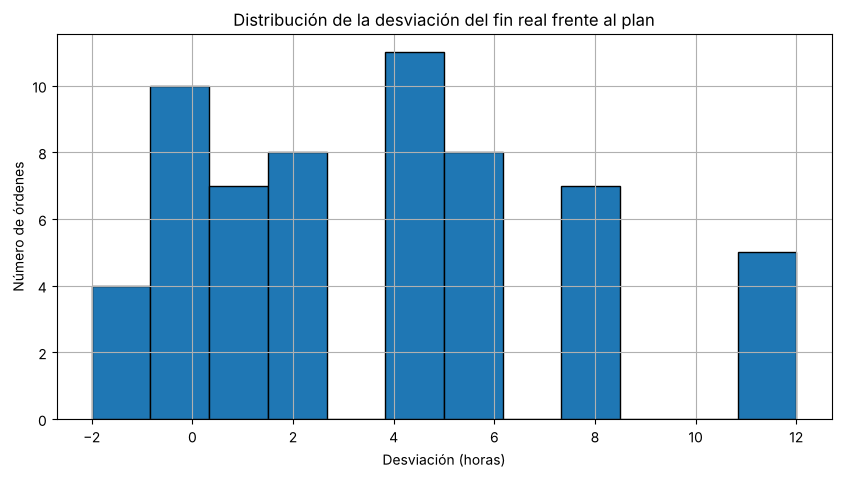

In [8]:
fig, ax = plt.subplots(figsize=(10,5))
serie = df_modelo["desviacion_fin_h"].dropna()
ax.hist(serie, bins=12, edgecolor="black")
ax.set_title("Distribución de la desviación del fin real frente al plan")
ax.set_xlabel("Desviación (horas)")
ax.set_ylabel("Número de órdenes")
plt.show()

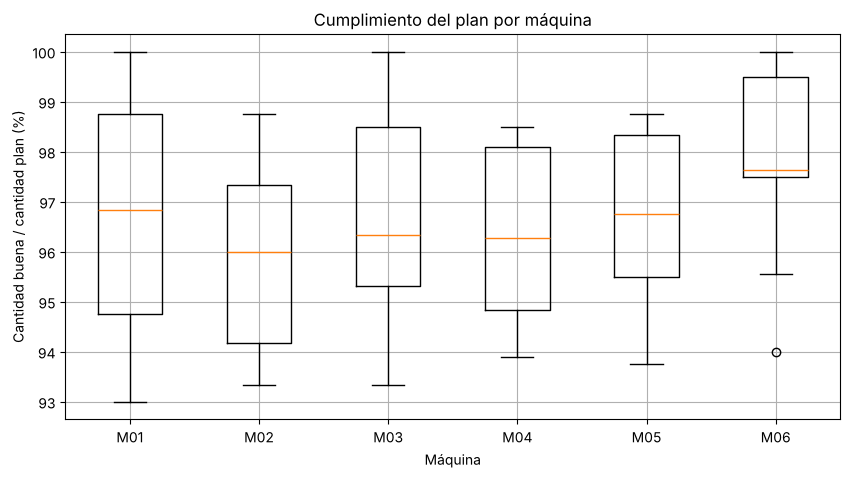

In [9]:
fig, ax = plt.subplots(figsize=(10,5))
grupos = []
etiquetas = []
for maquina, sub in df_modelo.groupby("maquina_id"):
    vals = sub["cumplimiento_plan_pct"].dropna().values
    if len(vals):
        grupos.append(vals); etiquetas.append(maquina)
ax.boxplot(grupos, showfliers=True)
ax.set_xticks(range(1, len(etiquetas) + 1))
ax.set_xticklabels(etiquetas)
ax.set_title("Cumplimiento del plan por máquina")
ax.set_xlabel("Máquina")
ax.set_ylabel("Cantidad buena / cantidad plan (%)")
plt.show()

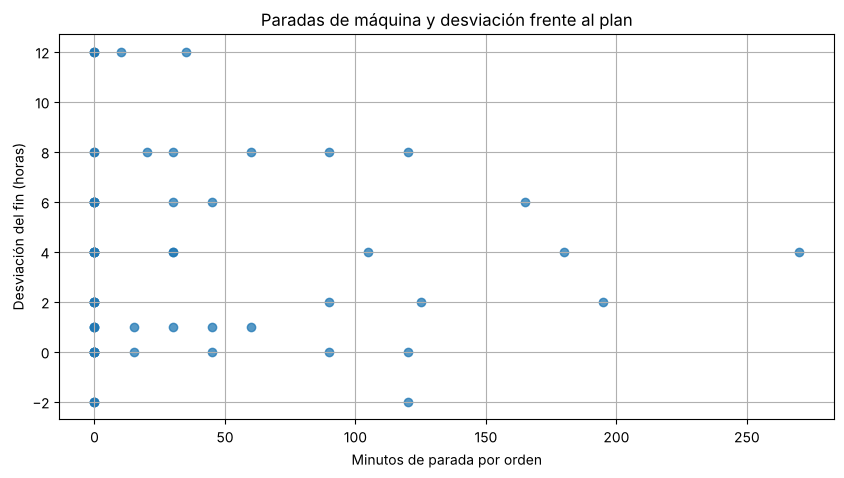

In [10]:
fig, ax = plt.subplots(figsize=(10,5))
ax.scatter(df_modelo["minutos_parada"], df_modelo["desviacion_fin_h"], alpha=0.75)
ax.set_title("Paradas de máquina y desviación frente al plan")
ax.set_xlabel("Minutos de parada por orden")
ax.set_ylabel("Desviación del fin (horas)")
plt.show()

### Interpretación de las tres gráficas
- **Histograma de la desviación del fin:** **46 de 60 órdenes (77%) terminan después de lo planificado**, con una mediana de 4 h y casos de hasta 12 h; solo 4 terminan antes. La distribución no es continua sino en escalones (0, 1, 2, 4, 6, 8, 12 h), una pista de que se originan por eventos discretos (p. ej., arranques tardíos de 2, 4 o 6 h).
- **Cumplimiento por máquina:** todas las máquinas están entre ≈93% y 100% de cumplimiento de lo planificado; las cajas casi se superponen, por lo que el **volumen producido no distingue** a unas máquinas de otras. El problema no es cuánto se produce sino **cuándo**.
- **Paradas vs. desviación del fin:** la nube no tiene tendencia (r ≈ −0.03). Más minutos de parada **no** se acompañan de más desviación.


Órdenes que terminan DESPUÉS del plan: 46 de 60 (76.7%)
Órdenes que ARRANCAN tarde: 30 de 59 con fecha de plan válida
                    retraso_arranque_h  exceso_duracion_h  desviacion_fin_h
retraso_arranque_h                1.00               0.49              0.96
exceso_duracion_h                 0.49               1.00              0.71
desviacion_fin_h                  0.96               0.71              1.00


,count,mean,std,min,25%,50%,75%,max
retraso_arranque_h,59.00,2.31,2.97,0.00,0.00,2.00,4.00,10.00
exceso_duracion_h,59.00,1.27,1.17,-2.00,1.00,2.00,2.00,2.00
desviacion_fin_h,60.00,3.72,3.81,-2.00,1.00,4.00,6.00,12.00


,ordenes,arranque_tarde_prom_h,exceso_duracion_prom_h,desviacion_fin_prom_h
maquina_id,,,,
M01,12,3.64,1.45,5.67
M03,8,3.00,1.62,4.62
M06,12,2.83,0.75,3.58
M02,9,1.78,1.33,3.11
M05,10,1.40,1.30,2.70
M04,8,1.00,1.25,2.25


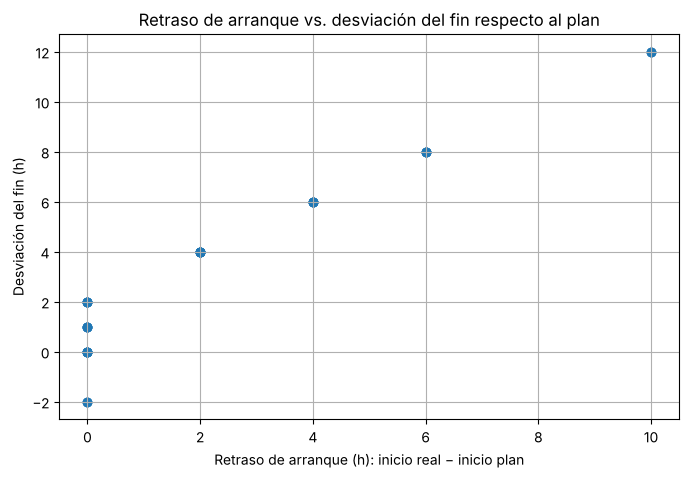

In [11]:
# 5.1 Evidencia adicional: ¿de dónde sale la desviación del fin respecto al plan?
ev = df_modelo.copy()
ev["retraso_arranque_h"] = (ev["inicio_real"] - ev["inicio_plan"]).dt.total_seconds()/3600
ev["exceso_duracion_h"]  = ev["duracion_real_h"] - (ev["fin_plan"] - ev["inicio_plan"]).dt.total_seconds()/3600

print(f"Órdenes que terminan DESPUÉS del plan: {(ev['desviacion_fin_h']>0).sum()} de {len(ev)} ({(ev['desviacion_fin_h']>0).mean()*100:.1f}%)")
print(f"Órdenes que ARRANCAN tarde: {(ev['retraso_arranque_h']>0).sum()} de {ev['retraso_arranque_h'].notna().sum()} con fecha de plan válida")
display(ev[["retraso_arranque_h","exceso_duracion_h","desviacion_fin_h"]].describe().T.round(2))
print(ev[["retraso_arranque_h","exceso_duracion_h","desviacion_fin_h"]].corr().round(2))

res_ini = (ev.groupby("maquina_id")
             .agg(ordenes=("orden_id","count"),
                  arranque_tarde_prom_h=("retraso_arranque_h","mean"),
                  exceso_duracion_prom_h=("exceso_duracion_h","mean"),
                  desviacion_fin_prom_h=("desviacion_fin_h","mean"))
             .round(2).sort_values("desviacion_fin_prom_h", ascending=False))
display(res_ini)

fig, ax = plt.subplots(figsize=(8,5))
ax.scatter(ev["retraso_arranque_h"], ev["desviacion_fin_h"], alpha=0.7)
ax.set_title("Retraso de arranque vs. desviación del fin respecto al plan")
ax.set_xlabel("Retraso de arranque (h): inicio real − inicio plan")
ax.set_ylabel("Desviación del fin (h)")
plt.show()

### Interpretación (¿de dónde sale la desviación del fin?)
- **Qué muestra:** la desviación del fin se correlaciona **0.96 con el retraso de arranque** (inicio real − inicio planificado) y 0.71 con el exceso de duración. **30 de 59 órdenes arrancan tarde** (2 a 10 h), mientras que la duración de ejecución solo excede el plan en promedio 1.3 h.
- **Por máquina:** M01 tiene el mayor arranque tardío (3.6 h) y la mayor desviación del fin (5.7 h); M04, la menor (1.0 h y 2.3 h).
- **Por qué importa:** la mayor parte del atraso al terminar no ocurre durante la producción sino **antes de empezar**. Es una pista de que el problema está en la liberación/alistamiento de la orden (material, operario, relevo de turno, máquina ocupada) más que en la velocidad de la máquina.
- **Cuidado:** es una relación en parte aritmética (el fin real = inicio real + duración), y no se conoce la causa del arranque tardío con estos datos.


### Pregunta orientadora 1
**¿Qué patrón es relevante para una decisión?**  
Selecciona una de las visualizaciones anteriores y explica qué decisión operacional podría verse afectada por el patrón observado. Evita limitarte a decir que “sube” o “baja”: conecta el patrón con capacidad, programación, calidad, inventario o servicio.

**Respuesta – Pregunta orientadora 1: ¿Qué patrón es relevante para una decisión?**

Elijo el **histograma de desviación del fin y su descomposición (5.1)**. El 77% de las órdenes termina después del plan y esa desviación se explica casi por completo por **arranques tardíos** (r = 0.96), no por paradas ni por baja productividad. La decisión de **programación** que cambia: en lugar de invertir primero en velocidad o en reducir paradas, conviene asegurar que cada orden **se libere y arranque a la hora programada** (verificar material, personal y máquina antes del turno, y dejar holgura en la secuencia). La máquina **M01** es la primera candidata: arranca en promedio 3.6 h tarde y concentra los retrasos de entrega (hallazgo 2). Esto afecta la **capacidad efectiva** (horas perdidas esperando) y el **nivel de servicio** (entregas tardías).


## 6. Detección de anomalías

Usaremos dos enfoques complementarios:
- **IQR:** identifica valores extremos por variable y es fácil de explicar.
- **Isolation Forest:** detecta combinaciones multivariadas poco frecuentes. Una anomalía estadística **no es automáticamente un error**; puede representar una condición real que exige investigación del proceso.

In [12]:
variables_anomalia = [
    "cantidad_plan","cantidad_buena","duracion_real_h","desviacion_fin_h",
    "cumplimiento_plan_pct","minutos_parada","minutos_setup","defectos_total",
    "inventario_promedio","brecha_inv_reorden","dias_retraso_calculado"
]
variables_anomalia = [c for c in variables_anomalia if c in df_modelo.columns]

def bandera_iqr(s):
    s = pd.to_numeric(s, errors="coerce")
    q1, q3 = s.quantile([0.25,0.75])
    iqr = q3-q1
    li, ls = q1-1.5*iqr, q3+1.5*iqr
    return (s<li) | (s>ls)

resumen_iqr=[]
for c in variables_anomalia:
    flag=bandera_iqr(df_modelo[c])
    df_modelo[f"anom_iqr_{c}"] = flag.fillna(False)
    resumen_iqr.append([c, int(flag.sum()), 100*flag.mean()])

pd.DataFrame(resumen_iqr, columns=["variable","anomalias_iqr","porcentaje"]).sort_values("anomalias_iqr", ascending=False)

,variable,anomalias_iqr,porcentaje
2,duracion_real_h,14,23.33
6,minutos_setup,14,23.33
5,minutos_parada,8,13.33
10,dias_retraso_calculado,1,1.67
0,cantidad_plan,0,0.00
1,cantidad_buena,0,0.00
4,cumplimiento_plan_pct,0,0.00
3,desviacion_fin_h,0,0.00
7,defectos_total,0,0.00
8,inventario_promedio,0,0.00


In [13]:
X = df_modelo[variables_anomalia].replace([np.inf,-np.inf],np.nan)
X_imp = X.fillna(X.median(numeric_only=True))

if len(X_imp) >= 20 and X_imp.shape[1] >= 2:
    iso = IsolationForest(contamination=0.08, random_state=42)
    df_modelo["anomalia_multivariada"] = (iso.fit_predict(X_imp) == -1)
else:
    df_modelo["anomalia_multivariada"] = False

cols_mostrar = ["orden_id","producto_id","maquina_id","anomalia_multivariada"] + variables_anomalia
anomalias = df_modelo.loc[df_modelo["anomalia_multivariada"], cols_mostrar]
anomalias.head(10)

,orden_id,producto_id,maquina_id,anomalia_multivariada,cantidad_plan,cantidad_buena,duracion_real_h,desviacion_fin_h,cumplimiento_plan_pct,minutos_parada,minutos_setup,defectos_total,inventario_promedio,brecha_inv_reorden,dias_retraso_calculado
14,OP0015,P008,M01,True,120.00,114.00,12.43,1.00,95.00,30.00,180.00,14.00,264.90,166.90,1.00
15,OP0016,P002,M04,True,300.00,283.00,18.57,4.00,94.33,0.00,20.00,0.00,196.69,103.84,2.00
22,OP0023,P007,M02,True,150.00,144.00,14.29,4.00,96.00,270.00,0.00,0.00,256.43,167.86,-2.00
29,OP0030,P006,M01,True,150.00,148.00,14.29,12.00,98.67,35.00,75.00,8.00,190.00,95.00,7.00
33,OP0034,P005,M04,True,300.00,294.00,17.57,1.00,98.00,0.00,0.00,14.00,144.54,50.69,0.00


### Interpretación de las anomalías
- **IQR:** `duracion_real_h` y `minutos_setup` marcan 14 órdenes cada una (23%), y `minutos_parada` marca 8 (13%). **No son 14 errores:** la duración depende del tamaño de lote (80 unidades ≈ 10 h; 300 unidades ≈ 18 h) y setup/paradas son 0 en la mayoría de las órdenes, por lo que cualquier valor mayor "se sale" del rango. IQR es una alerta, no un veredicto.
- **Isolation Forest (8%)** marca 5 órdenes: `OP0015` (M01, 180 min de setup y 14 defectos), `OP0016` y `OP0034` (lotes de 300), `OP0023` (270 min de parada) y `OP0030` (M01, 12 h de desviación y 7 días de retraso). Solo OP0023 coincide con los extremos de paradas; las demás son combinaciones inusuales, no valores extremos aislados.


In [14]:
# 6.1 Caso a caso: órdenes marcadas y coherencia entre fuentes
focos = ["OP0030","OP0019","OP0023"]
display(df_modelo.loc[df_modelo["orden_id"].isin(focos),
        ["orden_id","producto_id","maquina_id","turno","cantidad_plan","cantidad_buena","duracion_real_h","desviacion_fin_h",
         "eventos_total","minutos_parada","minutos_setup","defectos_total","dias_retraso_calculado"]])

print("Eventos de las órdenes foco:")
display(eventos[eventos["orden_id"].isin(focos)]
        [["orden_id","maquina_id","inicio_evento","fin_evento","tipo_evento","causa","duracion_reportada_min","duracion_calculada_min"]]
        .sort_values(["orden_id","inicio_evento"]))

# Coherencia temporal entre producción y entregas
chk = entregas.merge(ordenes[["orden_id","fin_real","inicio_plan"]], on="orden_id", how="inner")
antes_fin = (chk["fecha_real"].dt.normalize() < chk["fin_real"].dt.normalize()).sum()
prom_antes_inicio = (chk["fecha_prometida"] < chk["inicio_plan"].dt.normalize()).sum()
print(f"Entregas con fecha real ANTERIOR al fin real de producción: {antes_fin} de {len(chk)}")
print(f"Entregas con fecha prometida ANTERIOR al inicio planificado: {prom_antes_inicio} de {chk['inicio_plan'].notna().sum()} (con inicio_plan válido)")

Eventos de las órdenes foco:
Entregas con fecha real ANTERIOR al fin real de producción: 23 de 60
Entregas con fecha prometida ANTERIOR al inicio planificado: 22 de 59 (con inicio_plan válido)


,orden_id,producto_id,maquina_id,turno,cantidad_plan,cantidad_buena,duracion_real_h,desviacion_fin_h,eventos_total,minutos_parada,minutos_setup,defectos_total,dias_retraso_calculado
18,OP0019,P005,M06,A,NaN,145.00,13.29,1.00,4.00,60.00,120.00,3.00,0.00
22,OP0023,P007,M02,C,150.00,144.00,14.29,4.00,3.00,270.00,0.00,0.00,-2.00
29,OP0030,P006,M01,B,150.00,148.00,14.29,12.00,7.00,35.00,75.00,8.00,7.00


,orden_id,maquina_id,inicio_evento,fin_evento,tipo_evento,causa,duracion_reportada_min,duracion_calculada_min
83,OP0019,M06,2026-09-05 00:00:00,2026-09-05 00:45:00,Operación,Producción normal,45,45.00
67,OP0019,M06,2026-09-05 06:00:00,2026-09-05 06:45:00,Operación,Producción normal,45,45.00
117,OP0019,M06,2026-09-05 08:00:00,2026-09-05 10:00:00,Setup,Cambio de referencia,120,120.00
3,OP0019,M06,2026-09-05 15:00:00,2026-09-05 16:00:00,Parada,Falta de material,60,60.00
54,OP0023,M02,2026-09-07 07:00:00,2026-09-07 07:45:00,Operación,Producción normal,45,45.00
24,OP0023,M02,2026-09-07 08:00:00,2026-09-07 09:30:00,Parada,Ajuste de calidad,90,90.00
119,OP0023,M02,2026-09-07 09:00:00,2026-09-07 12:00:00,Parada,Microparada,180,180.00
10,OP0030,M01,2026-08-18 08:00:00,2026-08-18 08:15:00,Parada,Microparada,15,15.00
110,OP0030,M01,2026-08-18 10:00:00,2026-08-18 10:20:00,Parada,Microparada,20,20.00
144,OP0030,M01,2026-08-18 16:00:00,2026-08-18 17:30:00,Operación,Producción normal,90,90.00


### Interpretación (casos a investigar y coherencia entre fuentes)
- **OP0030 (M01, turno B)** – *condición real de operación, prioridad 1.* Tiene la mayor desviación del fin (**12 h**), el mayor retraso de entrega (**7 días**), **7 eventos** (2 microparadas, 2 setups por cambio de referencia y 3 de operación) y 8 defectos. Reúne varias señales en la máquina que más retrasa; no parece un error de captura.
- **OP0019 (M06)** – *error de datos.* `cantidad_plan = 0` pero se produjeron 145 unidades; además registra 120 min de setup y 60 de parada por falta de material. El 0 es un valor inválido (se puso vacío).
- **OP0023 (M02, turno C)** – *evento real, pero con un problema de registro.* 270 min de parada = *Ajuste de calidad* (08:00–09:30) + *Microparada* (09:00–12:00): los eventos **se solapan 30 min** (posible doble conteo) y una "microparada" de **3 horas** no es micro.
- **Coherencia entre fuentes:** **23 de 60 entregas** tienen fecha real anterior al fin de producción y **22 de 59** fecha prometida anterior al inicio planificado. Las fechas de Entregas no parecen ligadas a las órdenes de producción, lo que limita la confiabilidad de `dias_retraso_calculado`.


### Pregunta orientadora 2
**¿Qué anomalía requiere investigación del proceso?**  
Escoge al menos una orden marcada como anómala. Explica si podría ser un error de datos o una condición real de operación y qué evidencia adicional solicitarías antes de tomar una decisión.

**Respuesta – Pregunta orientadora 2: ¿Qué anomalía requiere investigación del proceso?**

**OP0030** (producto P006, máquina M01, turno B). No creo que sea un error de datos: los eventos están registrados con causa y horarios coherentes, y la orden acumula 12 h de desviación del fin, 7 días de retraso de entrega, 7 eventos (microparadas y cambios de referencia) y 8 defectos. Es una **condición real de operación** en la máquina que más retrasa. Antes de decidir solicitaría: (1) la bitácora del turno B del 18-19 de agosto (por qué se arrancó tarde, quién liberó la orden); (2) el estado de materiales y el cambio de referencia previo en M01; (3) el registro de no conformidades de los 8 defectos; (4) la fecha prometida y el despacho real de esa entrega (por la inconsistencia de fechas ya observada); y (5) si otras órdenes de M01 muestran el mismo patrón. Como casos secundarios: **OP0019** es un error de dato (plan = 0) y **OP0023** exige revisar el solapamiento de eventos y la definición de "microparada".


## 7. Correlación: relaciones lineales, no causalidad

La correlación resume asociación lineal. **No demuestra que una variable cause a otra.** Una relación puede estar explicada por una tercera variable, por selección de la muestra o por la propia estructura del proceso.

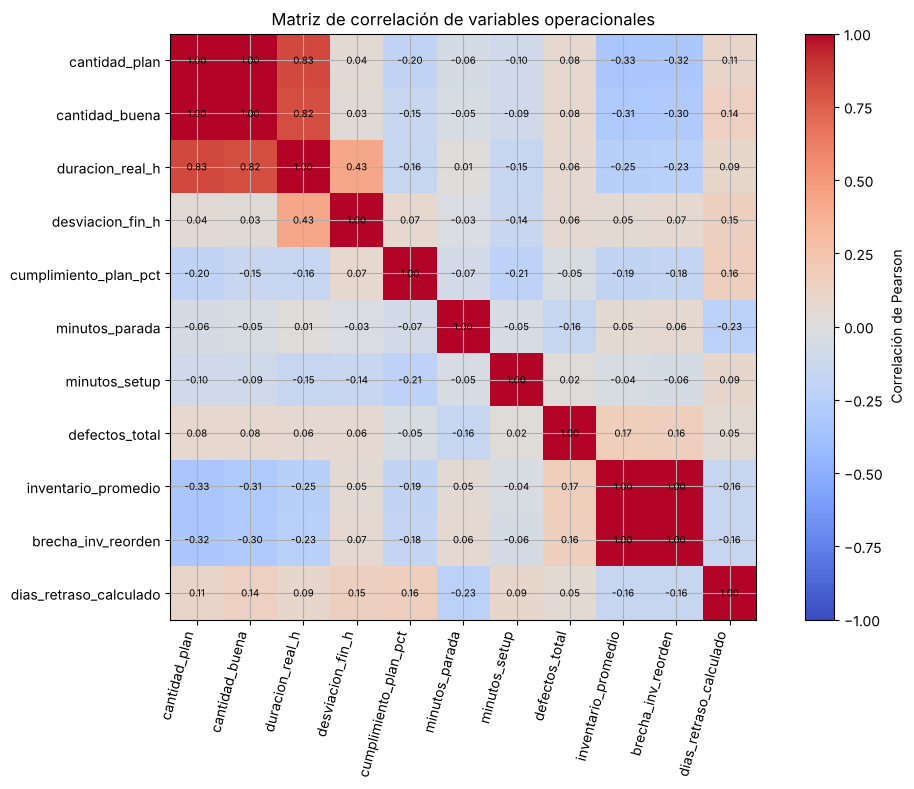

In [15]:
vars_corr = [
    "cantidad_plan","cantidad_buena","duracion_real_h","desviacion_fin_h",
    "cumplimiento_plan_pct","minutos_parada","minutos_setup","defectos_total",
    "inventario_promedio","brecha_inv_reorden","dias_retraso_calculado"
]
vars_corr = [c for c in vars_corr if c in df_modelo.columns]
corr = df_modelo[vars_corr].corr(numeric_only=True)

fig, ax = plt.subplots(figsize=(11,8))
im = ax.imshow(corr.values, vmin=-1, vmax=1, cmap="coolwarm")
n = len(corr.columns)
ax.set_xticks(range(n)); ax.set_xticklabels(corr.columns, rotation=75, ha="right")
ax.set_yticks(range(n)); ax.set_yticklabels(corr.index)
for i in range(n):
    for j in range(n):
        val = corr.iloc[i,j]
        if pd.notna(val):
            ax.text(j,i,f"{val:.2f}",ha="center",va="center",fontsize=7)
fig.colorbar(im, ax=ax, label="Correlación de Pearson")
ax.set_title("Matriz de correlación de variables operacionales")
plt.tight_layout(); plt.show()

In [16]:
# Pares de variables con correlación absoluta alta (excluye diagonal y duplicados)
pares=[]
for i in range(len(corr.columns)):
    for j in range(i+1,len(corr.columns)):
        v=corr.iloc[i,j]
        if pd.notna(v) and abs(v)>=0.70:
            pares.append([corr.columns[i],corr.columns[j],v])
pd.DataFrame(pares, columns=["variable_1","variable_2","correlacion"]).sort_values("correlacion", key=lambda s:s.abs(), ascending=False)

,variable_1,variable_2,correlacion
0,cantidad_plan,cantidad_buena,1.00
3,inventario_promedio,brecha_inv_reorden,1.00
1,cantidad_plan,duracion_real_h,0.83
2,cantidad_buena,duracion_real_h,0.82


### Interpretación de la matriz de correlación
- **Pares fuertes (|r| ≥ 0.70):** `cantidad_plan`–`cantidad_buena` (1.00), `inventario_promedio`–`brecha_inv_reorden` (1.00; la brecha es el inventario menos un punto de reorden casi constante, por construcción), y `cantidad_plan`/`cantidad_buena`–`duracion_real_h` (≈0.83): la duración crece con el lote. Son redundancias, no descubrimientos.
- **Con el retraso de entrega, ninguna variable supera |r| = 0.23**; la mayor es `minutos_parada`, con signo **negativo** (−0.23): más parada, *menos* retraso, contrario a la intuición. Eso exige una explicación, no una conclusión.


In [17]:
# 7.1 Evidencia para el par minutos_parada vs. dias_retraso_calculado y para los grupos
d = df_modelo.dropna(subset=["dias_retraso_calculado"])
print(f"Pearson : {d['minutos_parada'].corr(d['dias_retraso_calculado']):.3f}")
print(f"Spearman: {d['minutos_parada'].corr(d['dias_retraso_calculado'], method='spearman'):.3f}")

res_turno = (df_modelo.groupby("turno")
             .agg(ordenes=("orden_id","count"),
                  parada_prom_min=("minutos_parada","mean"),
                  parada_mediana_min=("minutos_parada","median"),
                  retraso_entrega_prom_dias=("dias_retraso_calculado","mean"),
                  desviacion_fin_prom_h=("desviacion_fin_h","mean"))
             .round(2))
display(res_turno)

res_maq = (df_modelo.groupby("maquina_id")
           .agg(ordenes=("orden_id","count"),
                con_dato_retraso=("dias_retraso_calculado","count"),
                retraso_entrega_prom_dias=("dias_retraso_calculado","mean"),
                parada_prom_min=("minutos_parada","mean"))
           .round(2))
res_maq["ordenes_tardias"] = df_modelo.assign(t=df_modelo["dias_retraso_calculado"]>0).groupby("maquina_id")["t"].sum()
display(res_maq.sort_values("retraso_entrega_prom_dias", ascending=False))

# M01 vs. resto (solo órdenes con dato de retraso): prueba exacta de Fisher
from scipy.stats import fisher_exact
m = d.dropna(subset=["maquina_id"]).copy()
m["tardia"] = m["dias_retraso_calculado"] > 0
tabla = pd.crosstab(m["maquina_id"]=="M01", m["tardia"])
tabla.index = ["Resto de máquinas","M01"]; tabla.columns = ["A tiempo o antes","Con retraso"]
display(tabla)
print(f"Fisher exacto M01 vs resto: p = {fisher_exact(tabla.loc[['M01','Resto de máquinas']].values)[1]:.4f}")

Pearson : -0.234
Spearman: -0.197
Fisher exacto M01 vs resto: p = 0.0041


,ordenes,parada_prom_min,parada_mediana_min,retraso_entrega_prom_dias,desviacion_fin_prom_h
turno,,,,,
A,29,21.03,0.00,1.79,3.79
B,15,34.67,20.00,0.87,4.33
C,16,65.00,30.00,0.13,3.00


,ordenes,con_dato_retraso,retraso_entrega_prom_dias,parada_prom_min,ordenes_tardias
maquina_id,,,,,
M01,12,11,2.45,38.33,9
M04,8,8,1.88,16.88,5
M05,10,10,0.70,31.50,2
M02,9,9,0.56,75.00,2
M03,8,8,0.50,30.00,2
M06,12,12,0.33,28.75,3


,A tiempo o antes,Con retraso
Resto de máquinas,33,14
M01,2,9


### Interpretación (paradas, turnos y máquinas)
- **Parada vs. retraso:** Pearson −0.23 y Spearman −0.20; débiles y de signo contrario al esperado.
- **Turnos:** el turno **C** tiene más parada (65 min promedio, mediana 30) y el **menor** retraso de entrega (0.13 días); el turno **A** tiene la menor parada (21 min, mediana 0) y el **mayor** retraso (1.79 días). La relación se invierte, lo que sugiere que el turno (o lo que se programa en cada uno) pesa más que las paradas.
- **Máquinas:** **M01 concentra los retrasos**: retraso promedio 2.45 días; **9 de 11 órdenes con dato llegan tarde (82%)** frente a **14 de 47 (30%)** en las demás (Fisher p ≈ 0.004). M02 es la que más para (75 min) pero casi no se retrasa (0.56 días). Con 12 órdenes y 6 máquinas comparadas, el resultado es una asociación que debe confirmarse.


### Pregunta orientadora 3
**¿Correlación implica causalidad?**  
Selecciona un par de variables correlacionadas. Propón al menos **dos explicaciones alternativas** a una relación causal directa y menciona qué información adicional necesitarías para investigarla.

**Respuesta – Pregunta orientadora 3: ¿Correlación implica causalidad?**

**No.** Tomo el par `minutos_parada` – `dias_retraso_calculado` (r = −0.23). Si la correlación implicara causalidad, "parar más reduciría el retraso", lo cual no tiene sentido operacional. Explicaciones alternativas respaldadas por los datos:
1. **Variable de confusión (turno y máquina):** el turno C concentra paradas (65 min) pero tiene el menor retraso (0.13 días), mientras que el A casi no para y es el más tardío (1.79 días); es probable que los productos, clientes o fechas prometidas asignados a cada turno/máquina expliquen el retraso, no las paradas.
2. **Las fuentes no están ligadas en el tiempo:** 23 de 60 entregas ocurren antes del fin de producción y 22 de 59 fechas prometidas son anteriores al inicio planificado; el retraso de entrega puede depender de cómo se fijan las promesas y no de lo que pasa en planta.
3. **Muestra pequeña y pocos casos extremos:** solo 27 órdenes tienen paradas y 8 son atípicas; unos pocos casos mueven la correlación.
Para investigarlo necesitaría: fecha y proceso de promesa al cliente, tipo de cliente/pedido, causa y momento de cada parada, y un periodo más largo (idealmente comparar mismas máquinas y productos con y sin parada).


## 8. Selección de variables: calidad, redundancia y sentido operacional

No existe una regla única. La decisión debe considerar:
- pertinencia para el problema;
- calidad y porcentaje de faltantes;
- redundancia con otras variables;
- disponibilidad antes del momento de decisión;
- riesgo de fuga de información (*data leakage*);
- interpretabilidad operacional.

In [18]:
candidatas = [c for c in vars_corr if c in df_modelo.columns]
resumen_variables = pd.DataFrame({
    "variable": candidatas,
    "faltantes_pct": [100*df_modelo[c].isna().mean() for c in candidatas],
    "unicos": [df_modelo[c].nunique(dropna=True) for c in candidatas],
    "correlacion_con_retraso": [
        df_modelo[[c,"dias_retraso_calculado"]].corr().iloc[0,1]
        if c != "dias_retraso_calculado" and "dias_retraso_calculado" in df_modelo.columns else np.nan
        for c in candidatas
    ]
})
resumen_variables

,variable,faltantes_pct,unicos,correlacion_con_retraso
0,cantidad_plan,1.67,8,0.11
1,cantidad_buena,1.67,42,0.14
2,duracion_real_h,0.00,19,0.09
3,desviacion_fin_h,0.00,8,0.15
4,cumplimiento_plan_pct,3.33,27,0.16
5,minutos_parada,0.00,16,-0.23
6,minutos_setup,0.00,11,0.09
7,defectos_total,0.00,18,0.05
8,inventario_promedio,0.00,8,-0.16
9,brecha_inv_reorden,0.00,8,-0.16


In [19]:
# Importancia exploratoria para predecir días de retraso.
# IMPORTANTE: la importancia de un modelo no sustituye la justificación operacional.
target = "dias_retraso_calculado"
predictoras = [c for c in candidatas if c != target]
base_rf = df_modelo[predictoras+[target]].replace([np.inf,-np.inf],np.nan).dropna(subset=[target])
X = base_rf[predictoras].fillna(base_rf[predictoras].median(numeric_only=True))
y = base_rf[target]

if len(base_rf) >= 20:
    rf = RandomForestRegressor(n_estimators=200, random_state=42, min_samples_leaf=3)
    rf.fit(X,y)
    importancia = (pd.DataFrame({"variable":predictoras,"importancia_exploratoria":rf.feature_importances_})
                   .sort_values("importancia_exploratoria",ascending=False))
else:
    importancia = pd.DataFrame({"variable":predictoras,"importancia_exploratoria":np.nan})
importancia

,variable,importancia_exploratoria
1,cantidad_buena,0.31
4,cumplimiento_plan_pct,0.20
7,defectos_total,0.14
3,desviacion_fin_h,0.08
2,duracion_real_h,0.07
8,inventario_promedio,0.05
5,minutos_parada,0.05
9,brecha_inv_reorden,0.04
6,minutos_setup,0.03
0,cantidad_plan,0.02


### Interpretación (resumen e importancia exploratoria)
- Faltantes bajos (≤3.3%), pero **`inventario_promedio` y `brecha_inv_reorden` solo tienen 8 valores distintos** (son por producto), y `cantidad_plan` tiene 8 valores únicos con 1 vacío.
- La "importancia" del Random Forest pone primero a `cantidad_buena` (0.31) y `cumplimiento_plan_pct` (0.20): **variables que solo se conocen al cerrar la orden** (fuga de información) y redundantes entre sí. Es un artefacto de la estructura de los datos, no una explicación operacional.
- La validación cruzada de la siguiente celda lo confirma: el modelo prácticamente no predice (R² promedio ≈ 0.04, con pliegues negativos). Con 59 órdenes y estas variables, **no se debe usar la importancia para justificar la selección**; por eso la decisión se basa en el sentido operacional, la disponibilidad temporal y la redundancia.


In [20]:
# 8.1 ¿Qué tan confiable es esa "importancia"? Validación cruzada del modelo exploratorio
from sklearn.model_selection import cross_val_score
r2 = cross_val_score(RandomForestRegressor(n_estimators=200, random_state=42, min_samples_leaf=3), X, y, cv=5, scoring="r2")
print("R² por pliegue:", r2.round(2), "| promedio:", round(r2.mean(), 2))
print("Un R² promedio cercano o menor a 0 indica que el modelo NO predice mejor que usar el promedio: la importancia no es evidencia de causa.")

R² por pliegue: [ 0.07 -0.03  0.21 -0.14  0.07] | promedio: 0.04
Un R² promedio cercano o menor a 0 indica que el modelo NO predice mejor que usar el promedio: la importancia no es evidencia de causa.


### Registro de decisión sobre variables

Completa el diccionario siguiente con **"Conservar"** o **"Descartar"** y escribe una justificación en `justificacion_variables`. No descartes una variable únicamente por baja correlación: puede aportar de forma no lineal o ser importante por conocimiento del proceso.

In [21]:
# Completa el diccionario con "Conservar" o "Descartar" y escribe una justificación.
# Pregunta analítica: ¿qué factores se relacionan con el retraso de entrega y con la desviación del fin respecto al plan?
decision_variables = {
    "cantidad_plan": "Conservar",
    "cantidad_buena": "Descartar",
    "duracion_real_h": "Descartar",
    "desviacion_fin_h": "Conservar",
    "cumplimiento_plan_pct": "Descartar",
    "minutos_parada": "Conservar",
    "minutos_setup": "Conservar",
    "defectos_total": "Conservar",
    "inventario_promedio": "Descartar",
    "brecha_inv_reorden": "Conservar",
    "dias_retraso_calculado": "Conservar",
}

justificacion_variables = {
    "cantidad_plan": "Se conoce antes de producir y define el tamaño de lote, que determina la duración (r≈0.83). Tiene 1 valor inválido (0) puesto en vacío.",
    "cantidad_buena": "Solo se conoce al cerrar la orden (riesgo de fuga) y es prácticamente redundante con cantidad_plan (r≈1.00). Domina la 'importancia' del modelo por esa razón, no por sentido operacional.",
    "duracion_real_h": "Se conoce al terminar y es consecuencia del lote (r≈0.82 con cantidad_buena). Se usa solo para construir indicadores (intensidad de parada, exceso de duración), no como predictora.",
    "desviacion_fin_h": "Conservar únicamente como variable respuesta secundaria (retraso en producción). Nunca como predictora del retraso de entrega: es posterior y casi idéntica al retraso de arranque (r≈0.96).",
    "cumplimiento_plan_pct": "Derivada de cantidad_buena/cantidad_plan (redundante), solo se conoce al cerrar y varía en un rango muy estrecho (≈93–100%). Se mantiene como KPI de reporte.",
    "minutos_parada": "Variable operacional central (capacidad/mantenimiento): se concentra en el turno C y en M02. Es de diagnóstico (se mide durante la ejecución). 55% de las órdenes tiene 0, por lo que se debe analizar con mediana y pruebas robustas.",
    "minutos_setup": "Mide alistamientos y cambios de referencia, relevantes para programación. 77% de las órdenes tiene 0 y 14 son anomalías IQR: conservar para investigar, sin eliminar.",
    "defectos_total": "Aporta la dimensión de calidad y se necesita para normalizarla por volumen (tasa de defectos) en pasos posteriores. Su baja correlación con el retraso (r≈0.05) no justifica descartarla.",
    "inventario_promedio": "Es un valor por producto (solo 8 valores distintos), promedia todo el periodo (incluye el futuro de cada orden) y es idéntica a brecha_inv_reorden en comportamiento (r=1.00).",
    "brecha_inv_reorden": "Se conserva por su sentido operacional (stock vs. punto de reorden), pero con cautela: es un promedio por producto, no el inventario al momento de iniciar cada orden. Reconstruirla a nivel de orden antes de modelar.",
    "dias_retraso_calculado": "Variable objetivo (nivel de servicio). 1 faltante (fecha_real vacía en ENT0006). No se usa como predictora.",
}

registro_variables = pd.DataFrame({
    "variable": candidatas,
    "decision": [decision_variables.get(c, "Pendiente") for c in candidatas],
    "justificacion": [justificacion_variables.get(c, "") for c in candidatas]
})
pd.set_option("display.max_colwidth", 250)
registro_variables

,variable,decision,justificacion
0,cantidad_plan,Conservar,"Se conoce antes de producir y define el tamaño de lote, que determina la duración (r≈0.83). Tiene 1 valor inválido (0) puesto en vacío."
1,cantidad_buena,Descartar,"Solo se conoce al cerrar la orden (riesgo de fuga) y es prácticamente redundante con cantidad_plan (r≈1.00). Domina la 'importancia' del modelo por esa razón, no por sentido operacional."
2,duracion_real_h,Descartar,"Se conoce al terminar y es consecuencia del lote (r≈0.82 con cantidad_buena). Se usa solo para construir indicadores (intensidad de parada, exceso de duración), no como predictora."
3,desviacion_fin_h,Conservar,Conservar únicamente como variable respuesta secundaria (retraso en producción). Nunca como predictora del retraso de entrega: es posterior y casi idéntica al retraso de arranque (r≈0.96).
4,cumplimiento_plan_pct,Descartar,"Derivada de cantidad_buena/cantidad_plan (redundante), solo se conoce al cerrar y varía en un rango muy estrecho (≈93–100%). Se mantiene como KPI de reporte."
5,minutos_parada,Conservar,"Variable operacional central (capacidad/mantenimiento): se concentra en el turno C y en M02. Es de diagnóstico (se mide durante la ejecución). 55% de las órdenes tiene 0, por lo que se debe analizar con mediana y pruebas robustas."
6,minutos_setup,Conservar,"Mide alistamientos y cambios de referencia, relevantes para programación. 77% de las órdenes tiene 0 y 14 son anomalías IQR: conservar para investigar, sin eliminar."
7,defectos_total,Conservar,Aporta la dimensión de calidad y se necesita para normalizarla por volumen (tasa de defectos) en pasos posteriores. Su baja correlación con el retraso (r≈0.05) no justifica descartarla.
8,inventario_promedio,Descartar,"Es un valor por producto (solo 8 valores distintos), promedia todo el periodo (incluye el futuro de cada orden) y es idéntica a brecha_inv_reorden en comportamiento (r=1.00)."
9,brecha_inv_reorden,Conservar,"Se conserva por su sentido operacional (stock vs. punto de reorden), pero con cautela: es un promedio por producto, no el inventario al momento de iniciar cada orden. Reconstruirla a nivel de orden antes de modelar."


### Resumen de la decisión de variables
- **Conservar:** `cantidad_plan`, `minutos_parada`, `minutos_setup`, `defectos_total`, `brecha_inv_reorden` (con cautela), `dias_retraso_calculado` (objetivo) y `desviacion_fin_h` (solo como respuesta secundaria); además las dos variables nuevas.
- **Descartar:** `cantidad_buena`, `cumplimiento_plan_pct` y `duracion_real_h` (posteriores al cierre y redundantes con el lote) e `inventario_promedio` (redundante con la brecha, por producto y con datos posteriores).
- **Criterios:** sentido operacional, calidad/faltantes, **disponibilidad al decidir (fuga)** y redundancia, no solo la correlación con el retraso.


## 9. Ingeniería de características: construye dos variables nuevas

Una buena característica traduce datos disponibles en una medida con **significado operacional**. Debe ser interpretable, calculable sin usar información futura y útil para una decisión.

Ejemplos de ideas (no obligatorias): intensidad de paradas respecto a la duración, presión de inventario frente al punto de reorden, defectos por unidad producida, desviación porcentual del ciclo o indicadores de cumplimiento.

**Tu tarea:** crea dos variables distintas a las que ya existen en `df_modelo`. Documenta nombre, fórmula, unidad, interpretación y decisión que podría apoyar.

In [22]:
# ===== TU DESARROLLO =====
NOMBRE_VAR_1 = "retraso_arranque_h"
NOMBRE_VAR_2 = "intensidad_parada_pct"

# 1) Retraso de arranque (h) = inicio real - inicio planificado (vacío si el inicio planificado es inválido)
df_modelo[NOMBRE_VAR_1] = (df_modelo["inicio_real"] - df_modelo["inicio_plan"]).dt.total_seconds() / 3600

# 2) Intensidad de parada (%) = minutos de parada / duración real de la orden (en minutos) x 100
df_modelo[NOMBRE_VAR_2] = 100 * df_modelo["minutos_parada"] / (df_modelo["duracion_real_h"] * 60)

print("Variable 1 definida:", bool(NOMBRE_VAR_1 and NOMBRE_VAR_1 in df_modelo.columns))
print("Variable 2 definida:", bool(NOMBRE_VAR_2 and NOMBRE_VAR_2 in df_modelo.columns))
display(df_modelo[[NOMBRE_VAR_1, NOMBRE_VAR_2]].describe().T.round(2))
print("Correlación con desviacion_fin_h y dias_retraso_calculado:")
display(df_modelo[[NOMBRE_VAR_1, NOMBRE_VAR_2, "desviacion_fin_h", "dias_retraso_calculado"]].corr().round(2).iloc[:2])

Variable 1 definida: True
Variable 2 definida: True
Correlación con desviacion_fin_h y dias_retraso_calculado:


,count,mean,std,min,25%,50%,75%,max
retraso_arranque_h,59.00,2.31,2.97,0.00,0.00,2.00,4.00,10.00
intensidad_parada_pct,60.00,4.56,7.46,0.00,0.00,0.00,5.11,31.50


,retraso_arranque_h,intensidad_parada_pct,desviacion_fin_h,dias_retraso_calculado
retraso_arranque_h,1.00,-0.07,0.96,0.19
intensidad_parada_pct,-0.07,1.00,-0.08,-0.25


In [23]:
# Describe aquí el sentido de tus nuevas variables.
documentacion_features = pd.DataFrame([
    {"variable": NOMBRE_VAR_1 or "Pendiente",
     "formula": "retraso_arranque_h = (inicio_real - inicio_plan) en horas",
     "unidad": "horas",
     "interpretacion_operacional": "Cuánto tarda en arrancar una orden respecto a la hora programada. 0 = arranque puntual; valores altos indican espera de material, operario, máquina o liberación de la orden. Se conoce al INICIAR la orden (antes de que termine), por lo que sirve como alerta temprana sin fuga de información.",
     "decision_que_apoya": "Programación y liberación de órdenes: revisar disponibilidad de recursos y relevos antes del arranque (especialmente en M01) y re-secuenciar cuando una orden ya arrancó tarde."},
    {"variable": NOMBRE_VAR_2 or "Pendiente",
     "formula": "intensidad_parada_pct = 100 * minutos_parada / (duracion_real_h * 60)",
     "unidad": "% de la duración de la orden",
     "interpretacion_operacional": "Parte del tiempo de la orden perdida en paradas. Alto = la orden estuvo detenida buena parte de su ejecución; normaliza las paradas por la duración, que cambia con el tamaño de lote. Se conoce al cerrar la orden (diagnóstico).",
     "decision_que_apoya": "Priorizar mantenimiento y análisis de causa raíz en las máquinas/turnos con mayor pérdida (M02, turno C), y comparar órdenes de distinta duración de forma justa."},
])
pd.set_option("display.max_colwidth", 400)
documentacion_features

,variable,formula,unidad,interpretacion_operacional,decision_que_apoya
0,retraso_arranque_h,retraso_arranque_h = (inicio_real - inicio_plan) en horas,horas,"Cuánto tarda en arrancar una orden respecto a la hora programada. 0 = arranque puntual; valores altos indican espera de material, operario, máquina o liberación de la orden. Se conoce al INICIAR la orden (antes de que termine), por lo que sirve como alerta temprana sin fuga de información.",Programación y liberación de órdenes: revisar disponibilidad de recursos y relevos antes del arranque (especialmente en M01) y re-secuenciar cuando una orden ya arrancó tarde.
1,intensidad_parada_pct,intensidad_parada_pct = 100 * minutos_parada / (duracion_real_h * 60),% de la duración de la orden,"Parte del tiempo de la orden perdida en paradas. Alto = la orden estuvo detenida buena parte de su ejecución; normaliza las paradas por la duración, que cambia con el tamaño de lote. Se conoce al cerrar la orden (diagnóstico).","Priorizar mantenimiento y análisis de causa raíz en las máquinas/turnos con mayor pérdida (M02, turno C), y comparar órdenes de distinta duración de forma justa."


In [24]:
# Se agregan las dos variables nuevas al registro de decisión
extra = pd.DataFrame([
    {"variable": NOMBRE_VAR_1, "decision": "Conservar",
     "justificacion": "Disponible al iniciar la orden (sin fuga) y explica casi toda la desviación del fin (r≈0.96). 1 vacío por inicio_plan inválido."},
    {"variable": NOMBRE_VAR_2, "decision": "Conservar",
     "justificacion": "Conservar como diagnóstico: normaliza las paradas por duración, pero se mide durante la ejecución y es muy redundante con minutos_parada (la duración varía poco). Útil para reportes y comparación entre máquinas."},
])
registro_variables = pd.concat([registro_variables, extra], ignore_index=True)
registro_variables

,variable,decision,justificacion
0,cantidad_plan,Conservar,"Se conoce antes de producir y define el tamaño de lote, que determina la duración (r≈0.83). Tiene 1 valor inválido (0) puesto en vacío."
1,cantidad_buena,Descartar,"Solo se conoce al cerrar la orden (riesgo de fuga) y es prácticamente redundante con cantidad_plan (r≈1.00). Domina la 'importancia' del modelo por esa razón, no por sentido operacional."
2,duracion_real_h,Descartar,"Se conoce al terminar y es consecuencia del lote (r≈0.82 con cantidad_buena). Se usa solo para construir indicadores (intensidad de parada, exceso de duración), no como predictora."
3,desviacion_fin_h,Conservar,Conservar únicamente como variable respuesta secundaria (retraso en producción). Nunca como predictora del retraso de entrega: es posterior y casi idéntica al retraso de arranque (r≈0.96).
4,cumplimiento_plan_pct,Descartar,"Derivada de cantidad_buena/cantidad_plan (redundante), solo se conoce al cerrar y varía en un rango muy estrecho (≈93–100%). Se mantiene como KPI de reporte."
5,minutos_parada,Conservar,"Variable operacional central (capacidad/mantenimiento): se concentra en el turno C y en M02. Es de diagnóstico (se mide durante la ejecución). 55% de las órdenes tiene 0, por lo que se debe analizar con mediana y pruebas robustas."
6,minutos_setup,Conservar,"Mide alistamientos y cambios de referencia, relevantes para programación. 77% de las órdenes tiene 0 y 14 son anomalías IQR: conservar para investigar, sin eliminar."
7,defectos_total,Conservar,Aporta la dimensión de calidad y se necesita para normalizarla por volumen (tasa de defectos) en pasos posteriores. Su baja correlación con el retraso (r≈0.05) no justifica descartarla.
8,inventario_promedio,Descartar,"Es un valor por producto (solo 8 valores distintos), promedia todo el periodo (incluye el futuro de cada orden) y es idéntica a brecha_inv_reorden en comportamiento (r=1.00)."
9,brecha_inv_reorden,Conservar,"Se conserva por su sentido operacional (stock vs. punto de reorden), pero con cautela: es un promedio por producto, no el inventario al momento de iniciar cada orden. Reconstruirla a nivel de orden antes de modelar."


## 10. Tres hallazgos sustentados

Un hallazgo debe contener **evidencia + interpretación + implicación para una decisión**. No escribas solamente “la variable X es alta”.

In [25]:
hallazgos = pd.DataFrame([
    {"hallazgo": 1,
     "evidencia_tabla_o_grafico": "Histograma de desviación del fin (46 de 60 órdenes terminan tarde, mediana 4 h) y celda 5.1: r = 0.96 entre retraso de arranque y desviación del fin; 30 de 59 órdenes arrancan tarde (media 2.3 h) y el exceso de duración promedia solo 1.3 h.",
     "interpretacion": "Casi todo el atraso del fin se origina antes de empezar la orden, no durante la producción: el cuello de botella parece estar en la liberación/alistamiento (material, personal, relevo, máquina ocupada). La relación es en parte aritmética y no se conoce la causa del arranque tardío.",
     "decision_o_accion": "Priorizar el control de arranque a la hora programada (chequeo previo de recursos, holgura en la secuencia) y medir retraso_arranque_h como indicador semanal; investigar las causas de arranque tardío antes de invertir en velocidad."},
    {"hallazgo": 2,
     "evidencia_tabla_o_grafico": "Celda 7.1: M01 tiene retraso de entrega promedio 2.45 días, con 9 de 11 órdenes tardías (82%) frente a 14 de 47 (30%) en las demás máquinas (Fisher p = 0.004); además tiene el mayor arranque tardío (3.6 h) y la mayor desviación del fin (5.7 h).",
     "interpretacion": "M01 concentra tanto los atrasos de producción como los de entrega, de forma coherente con el hallazgo 1. Es una asociación con 12 órdenes y sin controlar por producto, cliente o fechas prometidas; no es una causa demostrada.",
     "decision_o_accion": "Revisar primero la programación, la secuencia de referencias y la disponibilidad de M01 (y M04, con 1.9 días de retraso) y analizar OP0030 como caso guía."},
    {"hallazgo": 3,
     "evidencia_tabla_o_grafico": "Celdas 5, 7 y 7.1: minutos_parada vs. dias_retraso r = -0.23 (Spearman -0.20) y vs. desviación del fin r = -0.03. El turno C tiene más parada (65 min) y el menor retraso (0.13 días); el A, menos parada (21 min) y el mayor retraso (1.79 días).",
     "interpretacion": "Las paradas no explican los retrasos en estos datos; la relación inversa sugiere confusión por turno/máquina o por cómo se fijan las promesas (23 de 60 entregas ocurren antes del fin de producción). No se puede afirmar causalidad.",
     "decision_o_accion": "No justificar acciones de reducción de paradas por su efecto en el servicio sin más evidencia; atacar las paradas (turno C y M02) por eficiencia y revisar con Comercial/Logística cómo se registran y se prometen las fechas."},
])
pd.set_option("display.max_colwidth", 400)
hallazgos

,hallazgo,evidencia_tabla_o_grafico,interpretacion,decision_o_accion
0,1,"Histograma de desviación del fin (46 de 60 órdenes terminan tarde, mediana 4 h) y celda 5.1: r = 0.96 entre retraso de arranque y desviación del fin; 30 de 59 órdenes arrancan tarde (media 2.3 h) y el exceso de duración promedia solo 1.3 h.","Casi todo el atraso del fin se origina antes de empezar la orden, no durante la producción: el cuello de botella parece estar en la liberación/alistamiento (material, personal, relevo, máquina ocupada). La relación es en parte aritmética y no se conoce la causa del arranque tardío.","Priorizar el control de arranque a la hora programada (chequeo previo de recursos, holgura en la secuencia) y medir retraso_arranque_h como indicador semanal; investigar las causas de arranque tardío antes de invertir en velocidad."
1,2,"Celda 7.1: M01 tiene retraso de entrega promedio 2.45 días, con 9 de 11 órdenes tardías (82%) frente a 14 de 47 (30%) en las demás máquinas (Fisher p = 0.004); además tiene el mayor arranque tardío (3.6 h) y la mayor desviación del fin (5.7 h).","M01 concentra tanto los atrasos de producción como los de entrega, de forma coherente con el hallazgo 1. Es una asociación con 12 órdenes y sin controlar por producto, cliente o fechas prometidas; no es una causa demostrada.","Revisar primero la programación, la secuencia de referencias y la disponibilidad de M01 (y M04, con 1.9 días de retraso) y analizar OP0030 como caso guía."
2,3,"Celdas 5, 7 y 7.1: minutos_parada vs. dias_retraso r = -0.23 (Spearman -0.20) y vs. desviación del fin r = -0.03. El turno C tiene más parada (65 min) y el menor retraso (0.13 días); el A, menos parada (21 min) y el mayor retraso (1.79 días).",Las paradas no explican los retrasos en estos datos; la relación inversa sugiere confusión por turno/máquina o por cómo se fijan las promesas (23 de 60 entregas ocurren antes del fin de producción). No se puede afirmar causalidad.,No justificar acciones de reducción de paradas por su efecto en el servicio sin más evidencia; atacar las paradas (turno C y M02) por eficiencia y revisar con Comercial/Logística cómo se registran y se prometen las fechas.


## 11. Síntesis final

Responde antes de entregar:

1. **¿Qué patrón es relevante para una decisión?** Sustenta con una visualización o tabla.
2. **¿Correlación implica causalidad?** Explica con un ejemplo del caso.
3. **¿Qué anomalía requiere investigación del proceso?** Indica la orden y la evidencia adicional que solicitarías.
4. ¿Qué dos variables nuevas construiste y por qué tienen sentido operacional?
5. ¿Qué variables conservarías o descartarías y por qué?

In [26]:
respuestas_finales = {
    "patron_relevante": "El 77% de las órdenes termina después del plan y esa desviación se explica casi por completo por el arranque tardío (r = 0.96 con retraso_arranque_h; 30 de 59 órdenes arrancan tarde), no por las paradas (r = -0.03) ni por el volumen producido. Además, M01 concentra los retrasos de entrega (9 de 11 órdenes tardías vs. 30% en el resto; Fisher p = 0.004). Decisión: asegurar liberación y arranque puntual de las órdenes (empezando por M01) en lugar de enfocarse primero en paradas o velocidad.",
    "correlacion_y_causalidad": "No. Entre minutos_parada y dias_retraso_calculado la correlación es -0.23: parar más 'reduciría' el retraso, lo que no tiene sentido. Alternativas: (1) confusión por turno/máquina (el turno C para más y se retrasa menos; el A casi no para y se retrasa más); (2) las fechas de Entregas no están ligadas a la producción (23 de 60 entregas ocurren antes del fin real; 22 de 59 promesas son anteriores al inicio del plan); (3) muestra pequeña con pocos casos extremos. Se necesitaría el proceso de promesa al cliente, causa y momento de cada parada y un periodo más largo.",
    "anomalia_a_investigar": "OP0030 (P006, M01, turno B): 12 h de desviación del fin, 7 días de retraso de entrega, 7 eventos (microparadas y cambios de referencia) y 8 defectos. Parece una condición real de operación, no un error de datos. Evidencia a solicitar: bitácora del turno B del 18-19/08, estado de materiales y cambio de referencia en M01, no conformidades de la orden y fecha/despacho real de la entrega. Casos secundarios: OP0019 (cantidad_plan = 0, error de dato) y OP0023 (270 min de parada con eventos solapados y una 'microparada' de 3 h).",
    "variables_nuevas": "retraso_arranque_h = inicio_real - inicio_plan (h): se conoce al iniciar la orden, sin fuga de información, y explica la desviación del fin (r = 0.96); apoya la programación y liberación de órdenes. intensidad_parada_pct = 100 * minutos_parada / (duracion_real_h * 60): normaliza la parada por la duración de la orden; apoya la priorización de mantenimiento (M02, turno C) aunque se mide al cerrar la orden.",
    "seleccion_variables": "Conservar: cantidad_plan, minutos_parada, minutos_setup, defectos_total, brecha_inv_reorden (con cautela, es por producto), dias_retraso_calculado (objetivo), desviacion_fin_h (solo respuesta secundaria) y las dos variables nuevas. Descartar: cantidad_buena, cumplimiento_plan_pct y duracion_real_h (posteriores al cierre, redundantes con el lote; riesgo de fuga) e inventario_promedio (redundante con la brecha, valor por producto con datos posteriores). La importancia del Random Forest no se usó como criterio: el modelo no predice (R² ≈ 0.04).",
}
pd.Series(respuestas_finales, name="Respuesta").to_frame()

,Respuesta
patron_relevante,"El 77% de las órdenes termina después del plan y esa desviación se explica casi por completo por el arranque tardío (r = 0.96 con retraso_arranque_h; 30 de 59 órdenes arrancan tarde), no por las paradas (r = -0.03) ni por el volumen producido. Además, M01 concentra los retrasos de entrega (9 de 11 órdenes tardías vs. 30% en el resto; Fisher p = 0.004). Decisión: asegurar liberación y arranque puntual de las órdenes (empezando por M01) en lugar de enfocarse primero en paradas o velocidad."
correlacion_y_causalidad,"No. Entre minutos_parada y dias_retraso_calculado la correlación es -0.23: parar más 'reduciría' el retraso, lo que no tiene sentido. Alternativas: (1) confusión por turno/máquina (el turno C para más y se retrasa menos; el A casi no para y se retrasa más); (2) las fechas de Entregas no están ligadas a la producción (23 de 60 entregas ocurren antes del fin real; 22 de 59 promesas son anteriores al inicio del plan); (3) muestra pequeña con pocos casos extremos. Se necesitaría el proceso de promesa al cliente, causa y momento de cada parada y un periodo más largo."
anomalia_a_investigar,"OP0030 (P006, M01, turno B): 12 h de desviación del fin, 7 días de retraso de entrega, 7 eventos (microparadas y cambios de referencia) y 8 defectos. Parece una condición real de operación, no un error de datos. Evidencia a solicitar: bitácora del turno B del 18-19/08, estado de materiales y cambio de referencia en M01, no conformidades de la orden y fecha/despacho real de la entrega. Casos secundarios: OP0019 (cantidad_plan = 0, error de dato) y OP0023 (270 min de parada con eventos solapados y una 'microparada' de 3 h)."
variables_nuevas,"retraso_arranque_h = inicio_real - inicio_plan (h): se conoce al iniciar la orden, sin fuga de información, y explica la desviación del fin (r = 0.96); apoya la programación y liberación de órdenes. intensidad_parada_pct = 100 * minutos_parada / (duracion_real_h * 60): normaliza la parada por la duración de la orden; apoya la priorización de mantenimiento (M02, turno C) aunque se mide al cerrar la orden."
seleccion_variables,"Conservar: cantidad_plan, minutos_parada, minutos_setup, defectos_total, brecha_inv_reorden (con cautela, es por producto), dias_retraso_calculado (objetivo), desviacion_fin_h (solo respuesta secundaria) y las dos variables nuevas. Descartar: cantidad_buena, cumplimiento_plan_pct y duracion_real_h (posteriores al cierre, redundantes con el lote; riesgo de fuga) e inventario_promedio (redundante con la brecha, valor por producto con datos posteriores). La importancia del Random Forest no se usó como criterio: el modelo no predice (R² ≈ 0.04)."


## 12. Exportación opcional de evidencias

Si has diligenciado las secciones anteriores, puedes exportar las tablas de hallazgos, selección y documentación de características.

In [27]:
SALIDA = Path("RE03_Evidencias_Laboratorio2.xlsx")
with pd.ExcelWriter(SALIDA, engine="openpyxl") as writer:
    hallazgos.to_excel(writer, sheet_name="Hallazgos", index=False)
    registro_variables.to_excel(writer, sheet_name="Seleccion_variables", index=False)
    documentacion_features.to_excel(writer, sheet_name="Nuevas_variables", index=False)
    pd.Series(respuestas_finales, name="Respuesta").to_frame().to_excel(writer, sheet_name="Respuestas")
print("Archivo de evidencias:", SALIDA.resolve())

Archivo de evidencias: /tmp/claude-0/-home-claude/511b38ce-3933-502f-9a20-31ba98af1363/scratchpad/w/RE03_Evidencias_Laboratorio2.xlsx


## Referencias de apoyo

- Figueroa Martínez, C. A. (2026). *Laboratorio 2: exploración, visualización e ingeniería de características* [Notebook interactivo de Python y guía de interpretación]. Universidad Cooperativa de Colombia.
- James, G., Witten, D., Hastie, T., Tibshirani, R., & Taylor, J. (2023). *An introduction to statistical learning: With applications in Python*. Springer.
- McKinney, W. (2022). *Python for data analysis* (3rd ed.). O’Reilly Media.
- Pedregosa, F., et al. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825–2830.